In [1]:
import os
from PIL import Image

# Sesuaikan dengan nama folder Anda yang typo sebelumnya
SOURCE_DIR = "./orginal data" 
TARGET_DIR = "./resized_data"
NEW_SIZE = (128, 128)

os.makedirs(TARGET_DIR, exist_ok=True)

print("Mulai proses resize massal...")
count = 0

for root, dirs, files in os.walk(SOURCE_DIR):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            # Dapatkan nama kelas dari sub-folder
            class_name = os.path.basename(root)
            target_class_dir = os.path.join(TARGET_DIR, class_name)
            os.makedirs(target_class_dir, exist_ok=True)
            
            # Path asal dan tujuan
            img_path = os.path.join(root, file)
            target_path = os.path.join(target_class_dir, file)
            
            # Proses Buka -> Resize -> Simpan
            try:
                img = Image.open(img_path).convert('RGB')
                img = img.resize(NEW_SIZE, Image.Resampling.LANCZOS)
                img.save(target_path, quality=85)
                count += 1
            except Exception as e:
                print(f"Gagal memproses {file}: {e}")

print(f"Selesai! {count} gambar berhasil di-resize dan disimpan di folder '{TARGET_DIR}'.")

Mulai proses resize massal...
Selesai! 1400 gambar berhasil di-resize dan disimpan di folder './resized_data'.


In [2]:
# A. Import library
import copy
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.utils import make_grid

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay



In [3]:
# B. Konfigurasi
DATA_DIR = "./resized_data" # Ganti dengan path dataset Anda
IMG_SIZE   = 128
BATCH_SIZE = 32
N_EPOCHS   = 30
LR         = 0.001
SEED       = 42
USE_PRETRAINED = False # Anda bisa mengubah ini menjadi True jika ingin menggunakan Transfer Learning (misal: ResNet) untuk hasil yang jauh lebih maksimal.

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)
 
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Device:", device)

Device: mps


In [4]:
# C. Transform & Augmentasi (DITINGKATKAN)
if USE_PRETRAINED:
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
else:
    MEAN, STD = [0.5, 0.5, 0.5], [0.5, 0.5, 0.5]

# Penambahan Augmentasi untuk mencegah Overfitting pada dataset kecil
transform_train = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)), # Variasi ukuran crop
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20), # Ditingkatkan dari 10 ke 20 derajat
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2), # Variasi warna dan cahaya
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

transform_eval = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [5]:
# D. Import data & split
full_train = datasets.ImageFolder(DATA_DIR, transform=transform_train)
full_eval  = datasets.ImageFolder(DATA_DIR, transform=transform_eval)

class_names = full_train.classes
n_classes = len(class_names)
targets = np.array(full_train.targets)

print(f"Jumlah gambar: {len(full_train)} | Jumlah kelas: {n_classes}")
print("Kelas:", class_names)

# Split stratified 70 / 15 / 15
idx_all = np.arange(len(targets))
idx_train, idx_tmp = train_test_split(
    idx_all, test_size=0.30, stratify=targets, random_state=SEED)
idx_val, idx_test = train_test_split(
    idx_tmp, test_size=0.50, stratify=targets[idx_tmp], random_state=SEED)

# 3 baris ini TETAP (jangan dihapus)
trainset = Subset(full_train, idx_train)
valset   = Subset(full_eval,  idx_val)
testset  = Subset(full_eval,  idx_test)

# 3 baris ini DIGANTI menjadi seperti ini
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
valloader   = DataLoader(valset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
testloader  = DataLoader(testset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Train: {len(trainset)} | Val: {len(valset)} | Test: {len(testset)}")



Jumlah gambar: 1400 | Jumlah kelas: 5
Kelas: ['Chrysanthemum', 'Hibiscus', 'Marigold', 'Petuniya', 'Rose']
Train: 980 | Val: 210 | Test: 210


In [6]:
# E. Arsitektur CNN yang Ditingkatkan (DENGAN BATCHNORM & DROPOUT)
class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(ImprovedCNN, self).__init__()
        # Convolutional Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        
        # Convolutional Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        # Convolutional Block 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        self.pool = nn.MaxPool2d(2, 2)
        
        # Kalkulasi dimensi setelah 3 kali pooling: 128 -> 64 -> 32 -> 16
        linear_input_size = 128 * (IMG_SIZE // 8) * (IMG_SIZE // 8)
        
        # Fully Connected Layers
        self.fc1 = nn.Linear(linear_input_size, 512)
        self.bn4 = nn.BatchNorm1d(512)
        self.dropout = nn.Dropout(0.5) # Dropout untuk mencegah overfitting
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        
        x = x.view(x.size(0), -1) # Flatten
        
        x = F.relu(self.bn4(self.fc1(x)))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = ImprovedCNN(num_classes=n_classes).to(device)


In [7]:
# F. Loss, Optimizer, dan LR Scheduler
criterion = nn.CrossEntropyLoss()

# AdamW memiliki Weight Decay (L2 Norm) yang lebih baik untuk mencegah overfitting
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

# Menurunkan Learning Rate secara otomatis jika loss validasi tidak turun setelah 3 epoch
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

In [8]:
# G. Training Loop dengan Early Stopping Manual (Menyimpan model terbaik)
import time

best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("Mulai proses training...")
start_time = time.time()

for epoch in range(N_EPOCHS):
    print(f'Epoch {epoch+1}/{N_EPOCHS}')
    print('-' * 15)

    # Setiap epoch memiliki fase training dan validasi
    for phase in ['train', 'val']:
        if phase == 'train':
            model.train()  # Set model ke mode training
            dataloader = trainloader
        else:
            model.eval()   # Set model ke mode evaluasi
            dataloader = valloader

        running_loss = 0.0
        running_corrects = 0

        # Iterasi batch data
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Kosongkan gradient sebelumnya
            optimizer.zero_grad()

            # Proses Forward
            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                # Proses Backward & optimasi hanya saat fase training
                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            # Hitung statistik
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        # Hitung loss dan akurasi per epoch
        epoch_loss = running_loss / len(dataloader.dataset)
        epoch_acc = running_corrects.float() / len(dataloader.dataset)
        
        print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

        # Simpan histori untuk visualisasi grafik
        if phase == 'train':
            train_losses.append(epoch_loss)
            train_accs.append(epoch_acc.item())
        else:
            val_losses.append(epoch_loss)
            val_accs.append(epoch_acc.item())
            
            # Update learning rate scheduler berdasarkan loss validasi
            scheduler.step(epoch_loss)

            # Simpan bobot (weights) model jika akurasi validasinya paling tinggi
            if epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    print()

time_elapsed = time.time() - start_time
print(f'Training selesai dalam {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'Akurasi Validasi Terbaik: {best_acc:.4f}')


Mulai proses training...
Epoch 1/30
---------------


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Train Loss: 0.4605 Acc: 0.8306
Val Loss: 0.6533 Acc: 0.7667

Epoch 2/30
---------------
Train Loss: 0.2528 Acc: 0.9143
Val Loss: 0.1903 Acc: 0.9429

Epoch 3/30
---------------
Train Loss: 0.1875 Acc: 0.9255
Val Loss: 0.4333 Acc: 0.8476

Epoch 4/30
---------------
Train Loss: 0.1674 Acc: 0.9459
Val Loss: 0.1562 Acc: 0.9333

Epoch 5/30
---------------
Train Loss: 0.1125 Acc: 0.9704
Val Loss: 0.1224 Acc: 0.9619

Epoch 6/30
---------------
Train Loss: 0.1241 Acc: 0.9633
Val Loss: 0.2738 Acc: 0.8952

Epoch 7/30
---------------
Train Loss: 0.1002 Acc: 0.9745
Val Loss: 0.1102 Acc: 0.9429

Epoch 8/30
---------------
Train Loss: 0.0831 Acc: 0.9776
Val Loss: 0.1112 Acc: 0.9714

Epoch 9/30
---------------
Train Loss: 0.0992 Acc: 0.9633
Val Loss: 0.1164 Acc: 0.9619

Epoch 10/30
---------------
Train Loss: 0.1161 Acc: 0.9612
Val Loss: 0.0990 Acc: 0.9429

Epoch 11/30
---------------
Train Loss: 0.0643 Acc: 0.9837
Val Loss: 0.0773 Acc: 0.9762

Epoch 12/30
---------------
Train Loss: 0.0777 Acc: 0.976

Akurasi Data Test: 0.9667

Classification Report:
               precision    recall  f1-score   support

Chrysanthemum       0.93      0.95      0.94        44
     Hibiscus       0.94      1.00      0.97        29
     Marigold       1.00      0.96      0.98        51
     Petuniya       1.00      1.00      1.00        46
         Rose       0.95      0.93      0.94        40

     accuracy                           0.97       210
    macro avg       0.96      0.97      0.97       210
 weighted avg       0.97      0.97      0.97       210



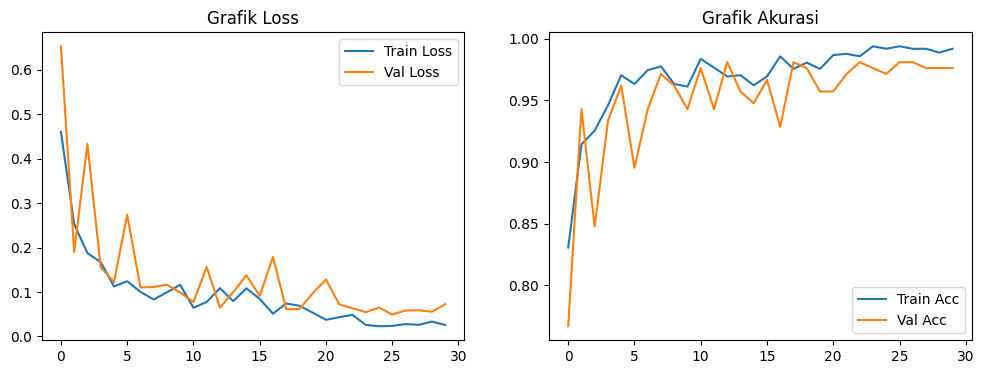

In [9]:
# H. Evaluasi Model pada Data Test
# Load bobot (weights) model terbaik yang didapat selama training
model.load_state_dict(best_model_wts)

model.eval()
test_corrects = 0
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        test_corrects += torch.sum(preds == labels.data)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = test_corrects.float() / len(testset)
print(f'Akurasi Data Test: {test_acc:.4f}')

# Tampilkan Laporan Klasifikasi (Precision, Recall, F1-Score)
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Plot Grafik Loss dan Akurasi (Opsional untuk Analisis)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.legend()
plt.title('Grafik Loss')

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.legend()
plt.title('Grafik Akurasi')
plt.show()

In [10]:
import os

for class_name in full_train.classes:
    folder = os.path.join(DATA_DIR, class_name)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    original = [f for f in files if not f.startswith("aug_")]
    augmented = [f for f in files if f.startswith("aug_")]

    print(
        class_name,
        "| Original:", len(original),
        "| Augmented:", len(augmented)
    )

Chrysanthemum | Original: 291 | Augmented: 0
Hibiscus | Original: 197 | Augmented: 0
Marigold | Original: 335 | Augmented: 0
Petuniya | Original: 309 | Augmented: 0
Rose | Original: 268 | Augmented: 0


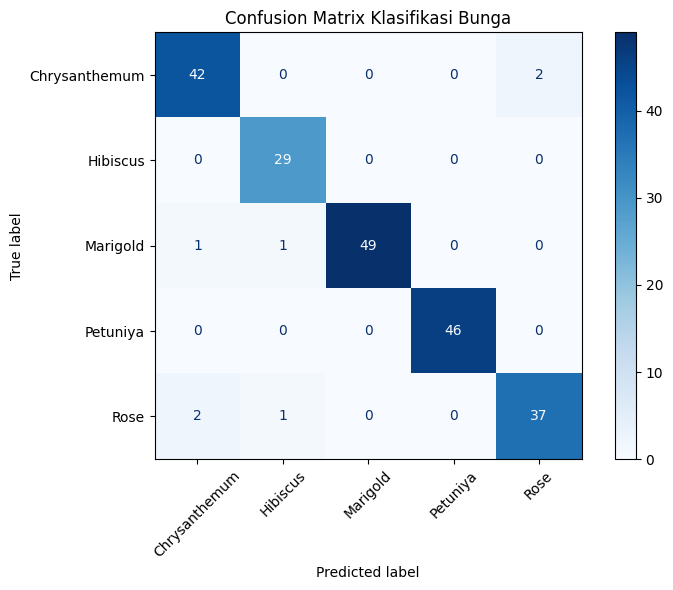

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Menghitung nilai matriks dari prediksi dan label asli
cm = confusion_matrix(all_labels, all_preds)

# Membuat visualisasi matriks
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Plot dengan skema warna biru dan memutar label teks agar tidak bertumpuk
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)

plt.title('Confusion Matrix Klasifikasi Bunga')
plt.tight_layout()
plt.show()

/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


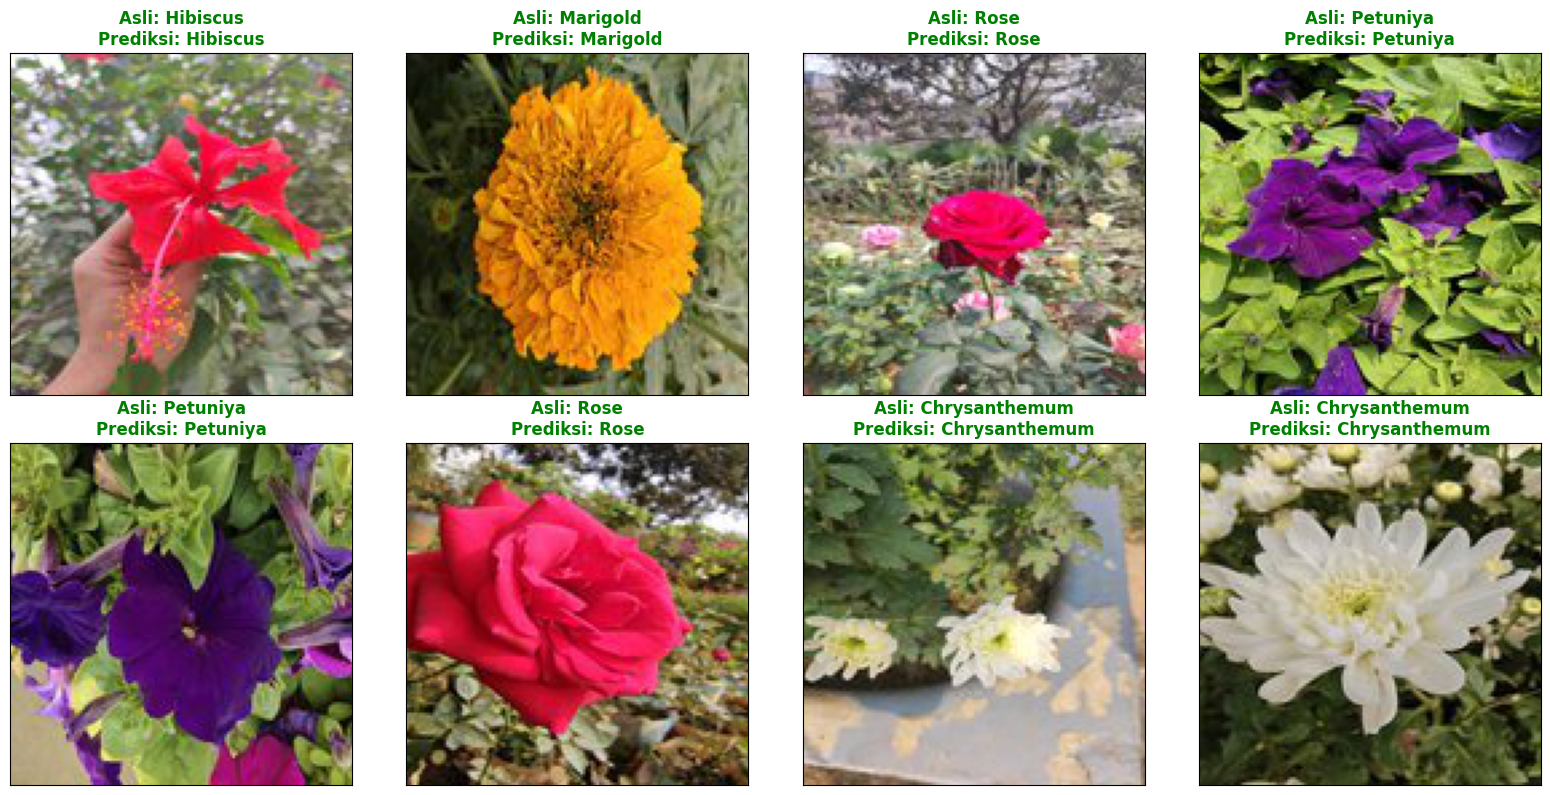

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Ambil 1 batch data gambar dari testloader
inputs, labels = next(iter(testloader))
inputs = inputs.to(device)
labels = labels.to(device)

# Lakukan prediksi pada batch tersebut
model.eval()
with torch.no_grad():
    outputs = model(inputs)
    _, preds = torch.max(outputs, 1)

# Siapkan kanvas untuk 8 gambar
fig = plt.figure(figsize=(16, 8))

for idx in range(8):
    ax = fig.add_subplot(2, 4, idx+1, xticks=[], yticks=[])
    
    # 1. Denormalisasi gambar agar warnanya kembali seperti asli (tidak pudar/gelap)
    img = inputs[idx].cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    # 2. Tampilkan gambar
    ax.imshow(img)
    
    # 3. Cek hasil: Hijau jika tebakan benar, Merah jika tebakan salah
    true_label = class_names[labels[idx]]
    pred_label = class_names[preds[idx]]
    color = "green" if true_label == pred_label else "red"
    
    # 4. Pasang judul
    ax.set_title(f"Asli: {true_label}\nPrediksi: {pred_label}", color=color, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn

class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(ImprovedCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
